In [1]:
print("Welcome to Task 3 - Salary Prediction!")

print("I am learning Machine Learning using Python.")

Welcome to Task 3 - Salary Prediction!
I am learning Machine Learning using Python.


In [2]:
import os

print(os.listdir('/content'))

['.config', 'salary_prediction_data.csv', 'sample_data']


In [3]:
import pandas as pd

In [4]:
import numpy as np

In [5]:
import matplotlib.pyplot as plt

In [6]:
import seaborn as sns

In [7]:
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
df = pd.read_csv('/content/salary_prediction_data.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
df.head()

,Education,Experience,Location,Job_Title,Age,Gender,Salary
0,High School,8,Urban,Manager,63,Male,84620.053665
1,PhD,11,Suburban,Director,59,Male,142591.255894
2,Bachelor,28,Suburban,Manager,61,Female,97800.255404
3,High School,29,Rural,Director,45,Male,96834.671282
4,PhD,25,Urban,Analyst,26,Female,132157.786175


In [14]:
df.tail()

,Education,Experience,Location,Job_Title,Age,Gender,Salary
995,High School,8,Suburban,Analyst,25,Female,64683.389864
996,High School,24,Urban,Engineer,30,Female,74468.205020
997,Master,18,Rural,Analyst,44,Male,98207.026024
998,Bachelor,27,Suburban,Director,31,Female,108544.922720
999,High School,25,Urban,Director,41,Female,71077.000066


In [15]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 7)


In [19]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1000
Number of Columns: 7


In [20]:
print("Dataset Columns:")

print(df.columns.tolist())

Dataset Columns:
['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender', 'Salary']


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Education   1000 non-null   object 
 1   Experience  1000 non-null   int64  
 2   Location    1000 non-null   object 
 3   Job_Title   1000 non-null   object 
 4   Age         1000 non-null   int64  
 5   Gender      1000 non-null   object 
 6   Salary      1000 non-null   float64
dtypes: float64(1), int64(2), object(4)
memory usage: 54.8+ KB


In [22]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
Education     0
Experience    0
Location      0
Job_Title     0
Age           0
Gender        0
Salary        0
dtype: int64


In [23]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [24]:
df.describe()

,Experience,Age,Salary
count,1000.000000,1000.000000,1000.000000
mean,14.771000,42.377000,105558.404239
std,8.341111,13.609412,28256.972075
min,1.000000,20.000000,33510.510669
25%,7.000000,30.000000,85032.141517
50%,15.000000,43.000000,104314.518315
75%,22.000000,55.000000,126804.047524
max,29.000000,64.000000,193016.602150


In [25]:
print(df.columns.tolist())

['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender', 'Salary']


In [27]:
df.isnull().sum()

,0
Education,0
Experience,0
Location,0
Job_Title,0
Age,0
Gender,0
Salary,0


In [28]:
df_clean = df.copy()

print("Dataset copied successfully!")

Dataset copied successfully!


In [29]:
print("Duplicates before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after cleaning:", df_clean.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [30]:
text_columns = df_clean.select_dtypes(
    include='object'
).columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

print("Extra spaces removed!")

Extra spaces removed!


In [31]:
print("Missing values before handling:")

print(df_clean.isnull().sum())

Missing values before handling:
Education     0
Experience    0
Location      0
Job_Title     0
Age           0
Gender        0
Salary        0
dtype: int64


In [32]:

print(df_clean.select_dtypes(include=np.number).columns.tolist())


print(df_clean.select_dtypes(include='object').columns.tolist())

['Experience', 'Age', 'Salary']
['Education', 'Location', 'Job_Title', 'Gender']


In [33]:
df_clean = df_clean.dropna(subset=['Salary'])

numerical_columns = df_clean.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:
    if column != 'Salary':
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].median()
        )

categorical_columns = df_clean.select_dtypes(
    include='object'
).columns

for column in categorical_columns:
    if df_clean[column].isnull().any():
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].mode()[0]
        )

print("Missing values handled!")

Missing values handled!


In [34]:
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())

print("\nRemaining Duplicates:")
print(df_clean.duplicated().sum())

Cleaned Dataset Shape: (1000, 7)

Remaining Missing Values:
Education     0
Experience    0
Location      0
Job_Title     0
Age           0
Gender        0
Salary        0
dtype: int64

Remaining Duplicates:
0


In [35]:
df_clean.to_csv(
    'Salary_Cleaned_Project3.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


In [38]:
print(df_clean.columns.tolist())

['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender', 'Salary']


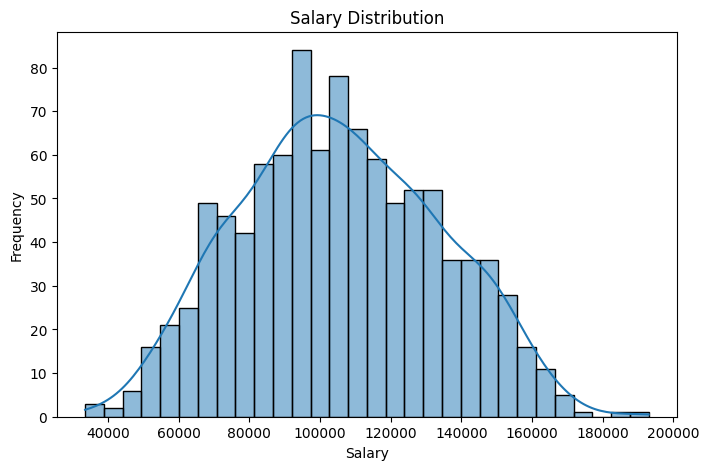

In [39]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df_clean,
    x='Salary',
    bins=30,
    kde=True
)

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

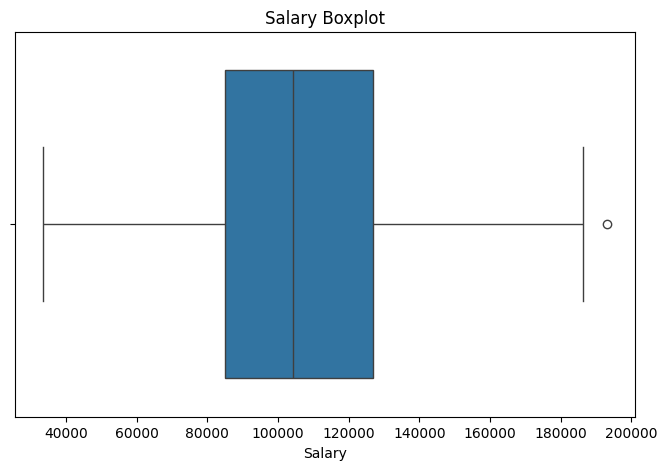

In [40]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df_clean, x='Salary')

plt.title('Salary Boxplot')
plt.xlabel('Salary')

plt.show()

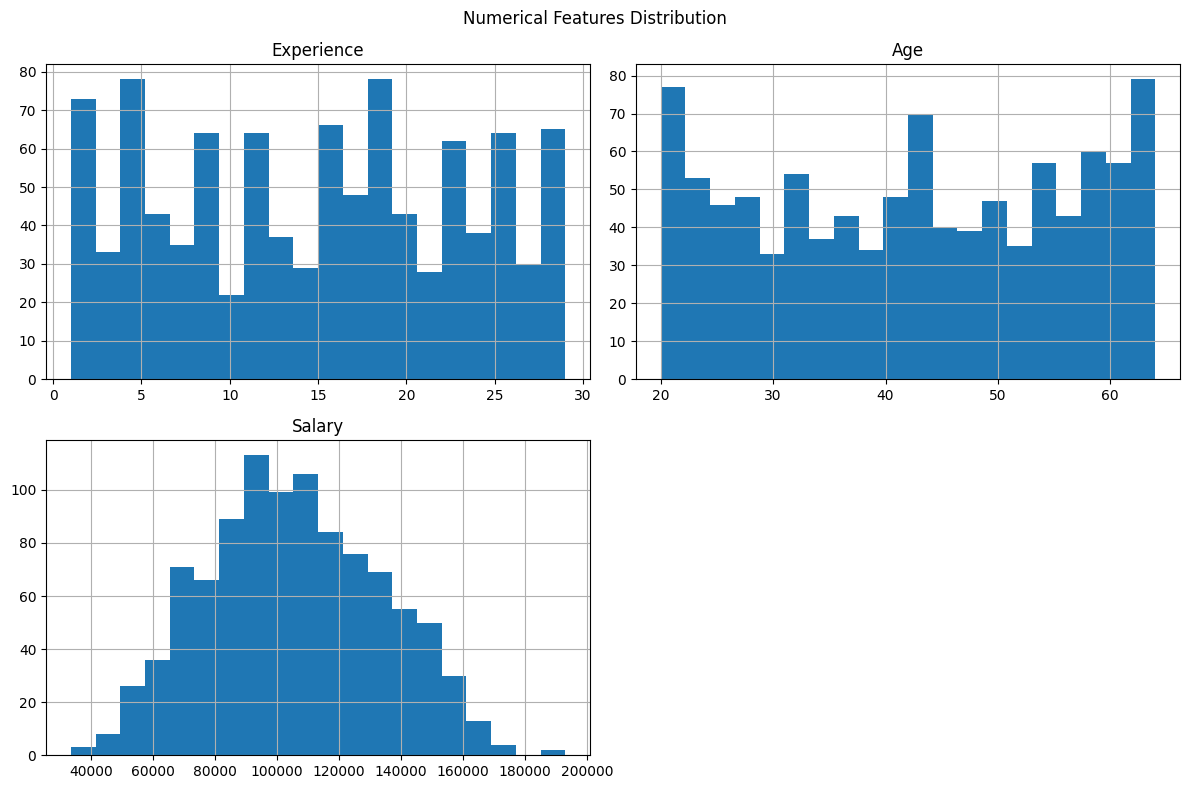

In [41]:
numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

df_clean[numeric_columns].hist(
    figsize=(12,8),
    bins=20
)

plt.suptitle('Numerical Features Distribution')
plt.tight_layout()
plt.show()

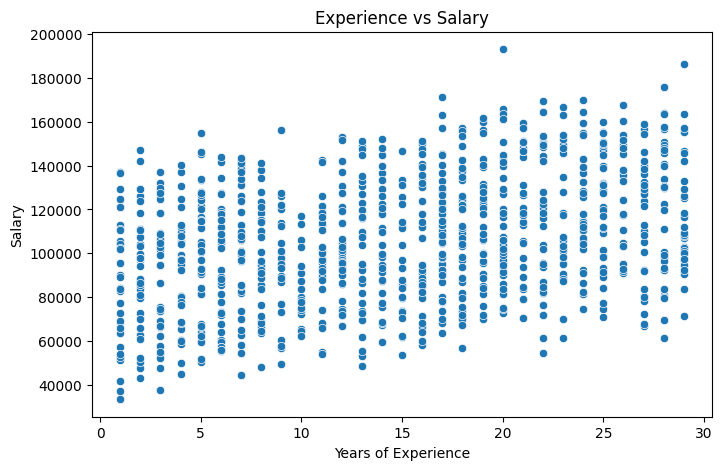

In [42]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_clean,
    x='Experience',
    y='Salary'
)

plt.title('Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.show()

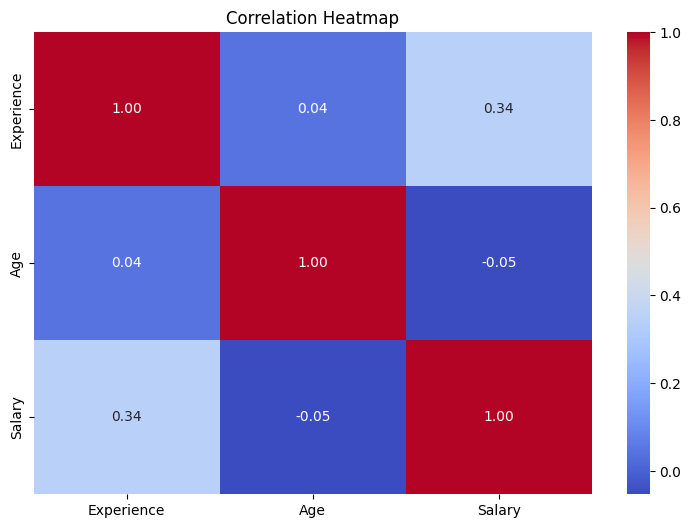

In [43]:
numeric_df = df_clean.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(9,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [44]:
print("Available Columns:")
print(df_clean.columns.tolist())

Available Columns:
['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender', 'Salary']


In [45]:
X = df_clean.drop('Salary', axis=1)
y = df_clean['Salary']

print("Input Features (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

Input Features (X):
     Education  Experience  Location Job_Title  Age  Gender
0  High School           8     Urban   Manager   63    Male
1          PhD          11  Suburban  Director   59    Male
2     Bachelor          28  Suburban   Manager   61  Female
3  High School          29     Rural  Director   45    Male
4          PhD          25     Urban   Analyst   26  Female

Target Variable (y):
0     84620.053665
1    142591.255894
2     97800.255404
3     96834.671282
4    132157.786175
Name: Salary, dtype: float64


In [46]:
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X.select_dtypes(include='object').columns.tolist()

print("Numerical Columns:", numerical_columns)
print("Categorical Columns:", categorical_columns)

Numerical Columns: ['Experience', 'Age']
Categorical Columns: ['Education', 'Location', 'Job_Title', 'Gender']


In [47]:
print("Dataset Columns:")
print(df_clean.columns.tolist())

print("\nNumerical Columns:")
print(df_clean.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df_clean.select_dtypes(include='object').columns.tolist())

Dataset Columns:
['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender', 'Salary']

Numerical Columns:
['Experience', 'Age', 'Salary']

Categorical Columns:
['Education', 'Location', 'Job_Title', 'Gender']


In [48]:
X = df_clean.drop(columns=['Salary'])
y = df_clean['Salary']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1000, 6)
y Shape: (1000,)


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (800, 6)
Testing Data: (200, 6)


In [50]:
print(df_clean.columns.tolist())

['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender', 'Salary']


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [52]:
numerical_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(include='object').columns.tolist()

print("Numerical Columns:", numerical_columns)
print("Categorical Columns:", categorical_columns)

Numerical Columns: ['Experience', 'Age']
Categorical Columns: ['Education', 'Location', 'Job_Title', 'Gender']


In [53]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [54]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', categorical_pipeline, categorical_columns)
])

In [56]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (800, 15)
Processed Testing Shape: (200, 15)


In [57]:
from sklearn.linear_model import LinearRegression

print("Linear Regression imported successfully!")

Linear Regression imported successfully!


In [58]:
model = LinearRegression()

print("Model created successfully!")

Model created successfully!


In [59]:
model.fit(X_train_processed, y_train)

print("Model trained successfully!")

Model trained successfully!


In [60]:
y_pred = model.predict(X_test_processed)

print("First 10 Predicted Salaries:")
print(y_pred[:10])

First 10 Predicted Salaries:
[ 80980.43421261  56651.22435371 110570.88965013  98116.1227683
  93708.60678003  66619.30093724  94437.56773835 118178.20629914
 121395.23554642 106625.37287326]


In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [62]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 8157.898478643166


In [63]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Squared Error (MSE): 105996277.66096857
Root Mean Squared Error (RMSE): 10295.449366636143


In [64]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)
print("R2 Score Percentage:", r2 * 100, "%")

R2 Score: 0.8701863681609703
R2 Score Percentage: 87.01863681609703 %


In [65]:
print("Salary Prediction Model Evaluation")
print("----------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Salary Prediction Model Evaluation
----------------------------------
MAE : 8157.898478643166
MSE : 105996277.66096857
RMSE: 10295.449366636143
R2 Score: 0.8701863681609703


In [66]:
comparison = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

comparison.head(10)

,Actual Salary,Predicted Salary
0,86677.840109,80980.434213
1,56036.163010,56651.224354
2,92226.871819,110570.889650
3,100710.088052,98116.122768
4,91775.012832,93708.606780
5,52282.492625,66619.300937
6,102139.813085,94437.567738
7,127491.152115,118178.206299
8,117342.186715,121395.235546
9,99647.042817,106625.372873


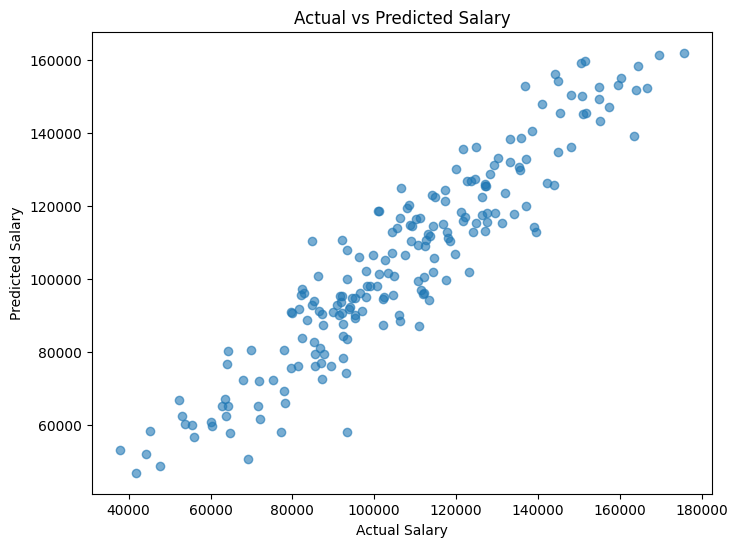

In [67]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()

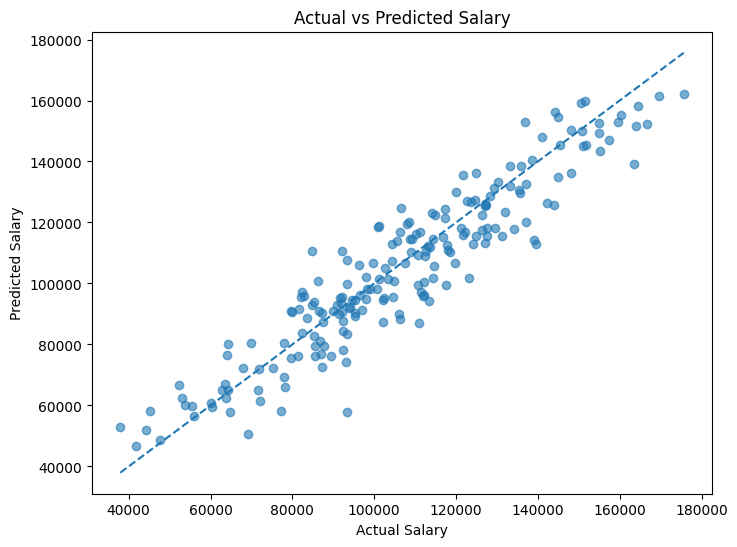

In [68]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

In [69]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [70]:
from sklearn.pipeline import Pipeline

salary_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [71]:
salary_pipeline.fit(X_train, y_train)

print("Complete pipeline trained successfully!")

Complete pipeline trained successfully!


In [72]:
joblib.dump(salary_pipeline, 'salary_prediction_project3.pkl')

print("Model saved successfully!")

Model saved successfully!


In [73]:
from google.colab import files

files.download('salary_prediction_project3.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
import joblib

loaded_model = joblib.load('salary_prediction_project3.pkl')

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [75]:
print(X.columns.tolist())

['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender']


In [79]:
new_employee = pd.DataFrame({
    'Age': [25],
    'Experience': [2],
    'Education': ['Bachelor'],
    'Location': ['New York'],
    'Gender': ['Male'],
    'Job_Title': ['Software Engineer']
})

In [80]:
predicted_salary = loaded_model.predict(new_employee)

print("Predicted Salary:", predicted_salary[0])

Predicted Salary: 81669.82925325503


In [81]:
print(X.columns.tolist())

['Education', 'Experience', 'Location', 'Job_Title', 'Age', 'Gender']


In [82]:
df_clean.to_csv('Salary_Cleaned_Project3.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [83]:
import os

print(os.listdir('/content'))

['.config', 'salary_prediction_project3.pkl', 'Salary_Cleaned_Project3.csv', 'salary_prediction_data.csv', 'sample_data']


In [84]:
from google.colab import files

files.download('Salary_Cleaned_Project3.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>